In [18]:

from pathlib import Path
import pandas as pd
import numpy as np

# -----------------------------
# 1. Configure paths
# -----------------------------
# Put this notebook in the same folder as the five CSV files,
# OR change DATA_DIR to the folder containing them.
DATA_DIR = Path.home() / "Downloads"
OUTPUT_DIR = DATA_DIR / "cleaned_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "transactions": DATA_DIR / "transactions.csv",
    "customers": DATA_DIR / "customers.csv",
    "products": DATA_DIR / "products.csv",
    "inventory": DATA_DIR / "inventory.csv",
    "campaigns": DATA_DIR / "campaigns.csv",
}

missing = [str(path) for path in FILES.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Could not find these CSV files:\n"
        + "\n".join(missing)
        + "\n\nPut all five CSVs in DATA_DIR or change DATA_DIR above."
    )

# Read IDs as strings so leading zeros are preserved.
transactions = pd.read_csv(FILES["transactions"], dtype={
    "transaction_id": "string", "customer_id": "string", "product_id": "string"
})
customers = pd.read_csv(FILES["customers"], dtype={"customer_id": "string"})
products = pd.read_csv(FILES["products"], dtype={"product_id": "string"})
inventory = pd.read_csv(FILES["inventory"], dtype={
    "inventory_record_id": "string", "product_id": "string"
})
campaigns = pd.read_csv(FILES["campaigns"], dtype={"campaign_id": "string"})

print("Loaded rows:")
for name, df in [
    ("transactions", transactions), ("customers", customers),
    ("products", products), ("inventory", inventory), ("campaigns", campaigns)
]:
    print(f"  {name:14s}: {len(df):,} rows, {len(df.columns)} columns")


Loaded rows:
  transactions  : 18,000 rows, 10 columns
  customers     : 3,000 rows, 5 columns
  products      : 250 rows, 5 columns
  inventory     : 5,000 rows, 7 columns
  campaigns     : 1,200 rows, 8 columns


In [19]:

# -----------------------------
# 2. General cleaning helpers
# -----------------------------
def clean_text_columns(df):
    """Trim whitespace from text columns without changing ID values otherwise."""
    df = df.copy()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace("", pd.NA)
    return df

def parse_date(df, column, errors="coerce"):
    df = df.copy()
    df[column] = pd.to_datetime(df[column], errors=errors)
    return df

def numeric_coerce(df, columns):
    df = df.copy()
    for col in columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

transactions = clean_text_columns(transactions)
customers = clean_text_columns(customers)
products = clean_text_columns(products)
inventory = clean_text_columns(inventory)
campaigns = clean_text_columns(campaigns)

# Remove only exact duplicate rows. We do NOT automatically remove duplicate IDs,
# because those require investigation rather than guesswork.
datasets = {
    "transactions": transactions,
    "customers": customers,
    "products": products,
    "inventory": inventory,
    "campaigns": campaigns,
}
exact_duplicate_counts = {}
for name, df in datasets.items():
    before = len(df)
    df = df.drop_duplicates().copy()
    exact_duplicate_counts[name] = before - len(df)
    datasets[name] = df

transactions = datasets["transactions"]
customers = datasets["customers"]
products = datasets["products"]
inventory = datasets["inventory"]
campaigns = datasets["campaigns"]

# Parse dates.
transactions = parse_date(transactions, "timestamp")
customers = parse_date(customers, "signup_date")
inventory = parse_date(inventory, "date")
campaigns = parse_date(campaigns, "date")

# Convert expected numeric columns safely.
transactions = numeric_coerce(transactions, ["quantity", "unit_price", "discount_pct"])
products = numeric_coerce(products, ["unit_cost", "list_price", "supplier_lead_days"])
inventory = numeric_coerce(inventory, [
    "stock_on_hand", "reorder_threshold", "stockout_flag", "supplier_delay_days"
])
campaigns = numeric_coerce(campaigns, ["spend", "impressions", "clicks", "conversions"])

print("Exact duplicate rows removed:")
for name, count in exact_duplicate_counts.items():
    print(f"  {name:14s}: {count}")


Exact duplicate rows removed:
  transactions  : 0
  customers     : 0
  products      : 0
  inventory     : 0
  campaigns     : 0


In [20]:

# -----------------------------
# 3. Audit key quality and values
# -----------------------------
def duplicate_key_report(df, key, label):
    if key not in df.columns:
        print(f"{label}: missing expected key column {key!r}")
        return
    n = int(df[key].duplicated(keep=False).sum())
    print(f"{label}: rows involved in duplicate {key} values = {n:,}")

print("Duplicate key checks:")
duplicate_key_report(transactions, "transaction_id", "transactions")
duplicate_key_report(customers, "customer_id", "customers")
duplicate_key_report(products, "product_id", "products")
duplicate_key_report(inventory, "inventory_record_id", "inventory")
duplicate_key_report(campaigns, "campaign_id", "campaigns")

# Basic invalid-value flags. Keep rows, add flags, and inspect before deciding
# whether any record should be excluded from a particular analysis.
transactions["quality_invalid_quantity"] = transactions["quantity"].isna() | (transactions["quantity"] <= 0)
transactions["quality_invalid_unit_price"] = transactions["unit_price"].isna() | (transactions["unit_price"] < 0)
transactions["quality_invalid_discount"] = transactions["discount_pct"].isna() | (transactions["discount_pct"] < 0) | (transactions["discount_pct"] > 1)
transactions["quality_invalid_timestamp"] = transactions["timestamp"].isna()

inventory["quality_invalid_stock"] = inventory["stock_on_hand"].isna() | (inventory["stock_on_hand"] < 0)
inventory["quality_invalid_threshold"] = inventory["reorder_threshold"].isna() | (inventory["reorder_threshold"] < 0)
inventory["quality_invalid_date"] = inventory["date"].isna()

campaigns["quality_clicks_gt_impressions"] = (
    campaigns["clicks"].notna() & campaigns["impressions"].notna()
    & (campaigns["clicks"] > campaigns["impressions"])
)
campaigns["quality_conversions_gt_clicks"] = (
    campaigns["conversions"].notna() & campaigns["clicks"].notna()
    & (campaigns["conversions"] > campaigns["clicks"])
)
campaigns["quality_invalid_campaign_values"] = (
    campaigns[["spend", "impressions", "clicks", "conversions"]].isna().any(axis=1)
    | (campaigns[["spend", "impressions", "clicks", "conversions"]] < 0).any(axis=1)
    | campaigns["date"].isna()
)

# Status and category values are not rewritten automatically; print them for review.
print("\nTransaction statuses:", sorted(transactions["status"].dropna().astype(str).unique()))
print("Sales channels:", sorted(transactions["channel"].dropna().astype(str).unique()))
print("Product categories:", sorted(products["category"].dropna().astype(str).unique()))

print("\nQuality flag counts:")
for col in [c for c in transactions.columns if c.startswith("quality_")]:
    print(f"  transactions.{col}: {int(transactions[col].sum()):,}")
for col in [c for c in inventory.columns if c.startswith("quality_")]:
    print(f"  inventory.{col}: {int(inventory[col].sum()):,}")
for col in [c for c in campaigns.columns if c.startswith("quality_")]:
    print(f"  campaigns.{col}: {int(campaigns[col].sum()):,}")

# Referential integrity checks.
customer_ids = set(customers["customer_id"].dropna())
product_ids = set(products["product_id"].dropna())
print("\nUnmatched transaction customer IDs:",
      int((~transactions["customer_id"].isin(customer_ids)).sum()))
print("Unmatched transaction product IDs:",
      int((~transactions["product_id"].isin(product_ids)).sum()))
print("Inventory product IDs missing from products:",
      int((~inventory["product_id"].isin(product_ids)).sum()))


Duplicate key checks:
transactions: rows involved in duplicate transaction_id values = 0
customers: rows involved in duplicate customer_id values = 0
products: rows involved in duplicate product_id values = 0
inventory: rows involved in duplicate inventory_record_id values = 0
campaigns: rows involved in duplicate campaign_id values = 0

Transaction statuses: ['Cancelled', 'Completed', 'Pending', 'Returned']
Sales channels: ['App', 'Store', 'Web']
Product categories: ['Beauty', 'Electronics', 'Fashion', 'Grocery', 'Home', 'Sports']

Quality flag counts:
  transactions.quality_invalid_quantity: 0
  transactions.quality_invalid_unit_price: 0
  transactions.quality_invalid_discount: 0
  transactions.quality_invalid_timestamp: 0
  inventory.quality_invalid_stock: 0
  inventory.quality_invalid_threshold: 0
  inventory.quality_invalid_date: 0
  campaigns.quality_clicks_gt_impressions: 84
  campaigns.quality_conversions_gt_clicks: 88
  campaigns.quality_invalid_campaign_values: 0

Unmatched t

In [21]:

# -----------------------------
# 4. Clean master tables and deduplicate inventory snapshots
# -----------------------------
# For master tables, keep the first row for duplicate IDs but write duplicates
# to the audit report. For a serious project, review these rows manually first.
customers_duplicate_ids = customers[customers["customer_id"].duplicated(keep=False)].copy()
products_duplicate_ids = products[products["product_id"].duplicated(keep=False)].copy()

customers_clean = customers.drop_duplicates(subset=["customer_id"], keep="first").copy()
products_clean = products.drop_duplicates(subset=["product_id"], keep="first").copy()

# Inventory can have several records for the same product/date.
# We aggregate those records rather than arbitrarily selecting a row:
# - median stock and supplier delay
# - maximum reorder threshold
# - maximum stockout flag
# - count of source records
# This is a documented compromise. Review duplicate groups if conflicting records
# matter to your business use case.
inventory_valid_dates = inventory[inventory["date"].notna()].copy()
inventory_daily = (
    inventory_valid_dates
    .groupby(["product_id", "date"], as_index=False, dropna=False)
    .agg(
        stock_on_hand=("stock_on_hand", "median"),
        reorder_threshold=("reorder_threshold", "max"),
        stockout_flag=("stockout_flag", "max"),
        supplier_delay_days=("supplier_delay_days", "median"),
        inventory_source_rows=("inventory_record_id", "size"),
        inventory_record_ids=("inventory_record_id", lambda s: " | ".join(s.dropna().astype(str)))
    )
)
inventory_daily["inventory_duplicate_date_group"] = inventory_daily["inventory_source_rows"] > 1
inventory_daily["inventory_below_reorder_threshold"] = (
    inventory_daily["stock_on_hand"].notna()
    & inventory_daily["reorder_threshold"].notna()
    & (inventory_daily["stock_on_hand"] <= inventory_daily["reorder_threshold"])
)

# Join transactions to customer and product master data.
# Validate many-to-one joins so duplicate master IDs cannot multiply transactions.
tx = transactions.merge(
    customers_clean, on="customer_id", how="left", validate="many_to_one",
    suffixes=("", "_customer")
)
tx = tx.merge(
    products_clean, on="product_id", how="left", validate="many_to_one",
    suffixes=("", "_product")
)

# Create a candidate discounted line value. Confirm the meaning of unit_price and
# discount_pct before treating this as official revenue.
tx["gross_line_value"] = tx["quantity"] * tx["unit_price"]
tx["estimated_discount_value"] = tx["gross_line_value"] * tx["discount_pct"]
tx["estimated_discounted_line_value"] = (
    tx["gross_line_value"] * (1 - tx["discount_pct"])
)
tx["estimated_line_cost"] = tx["quantity"] * tx["unit_cost"]
tx["estimated_line_margin_before_returns"] = (
    tx["estimated_discounted_line_value"] - tx["estimated_line_cost"]
)

# As-of join: attach the latest inventory snapshot on or before the transaction
# timestamp, for the same product. This does NOT mean inventory was continuously
# observed between dates. The age column helps identify stale snapshots.
tx = tx[tx["timestamp"].notna()].copy()
tx["transaction_date"] = tx["timestamp"].dt.normalize()
inventory_for_join = inventory_daily.rename(columns={"date": "inventory_date"}).copy()

tx_sorted = tx.sort_values(["timestamp", "product_id"]).copy()
inv_sorted = inventory_for_join.sort_values(["inventory_date", "product_id"]).copy()

# merge_asof requires sorting on the as-of key. Sorting globally by the date/time
# first, then by product, satisfies pandas' ordering requirement.
tx_sorted = tx.sort_values(["timestamp", "product_id"]).copy()
inv_sorted = inventory_for_join.sort_values(["inventory_date", "product_id"]).copy()

master = pd.merge_asof(
    tx_sorted,
    inv_sorted,
    left_on="timestamp",
    right_on="inventory_date",
    by="product_id",
    direction="backward",
    allow_exact_matches=True
)
master["inventory_snapshot_age_days"] = (
    master["timestamp"].dt.normalize() - master["inventory_date"]
).dt.days
master["inventory_snapshot_stale_over_30_days"] = (
    master["inventory_snapshot_age_days"].notna()
    & (master["inventory_snapshot_age_days"] > 30)
)

print("Transaction rows before joins:", len(transactions))
print("Transaction rows in master:", len(master))
print("Master row count preserved:", len(master) == int(transactions["timestamp"].notna().sum()))


Transaction rows before joins: 18000
Transaction rows in master: 18000
Master row count preserved: True


In [22]:

# -----------------------------
# 5. Save outputs
# -----------------------------
master_path = OUTPUT_DIR / "retail_master_transactions.csv"
master.to_csv(master_path, index=False)

customers_clean.to_csv(OUTPUT_DIR / "customers_clean.csv", index=False)
products_clean.to_csv(OUTPUT_DIR / "products_clean.csv", index=False)
inventory_daily.to_csv(OUTPUT_DIR / "inventory_daily_clean.csv", index=False)
campaigns.to_csv(
    OUTPUT_DIR / "campaigns_clean_with_quality_flags.csv",
    index=False
)

# Save records requiring manual review
customers_duplicate_ids.to_csv(
    OUTPUT_DIR / "review_duplicate_customer_ids.csv", index=False
)
products_duplicate_ids.to_csv(
    OUTPUT_DIR / "review_duplicate_product_ids.csv", index=False
)

inventory[
    inventory.duplicated(["product_id", "date"], keep=False)
].to_csv(
    OUTPUT_DIR / "review_duplicate_inventory_product_dates.csv",
    index=False
)

campaigns[
    campaigns["quality_clicks_gt_impressions"]
    | campaigns["quality_conversions_gt_clicks"]
].to_csv(
    OUTPUT_DIR / "review_campaign_metric_anomalies.csv",
    index=False
)

# Create audit summary
audit_rows = []

for name, df in [
    ("transactions_cleaned", transactions),
    ("customers_cleaned", customers_clean),
    ("products_cleaned", products_clean),
    ("inventory_daily_cleaned", inventory_daily),
    ("campaigns_with_flags", campaigns),
    ("master_transactions", master),
]:
    audit_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
    })

# Save audit report
pd.DataFrame(audit_rows).to_csv(
    OUTPUT_DIR / "audit_summary.csv",
    index=False
)

# Final confirmation
print("\nFinished. Outputs saved to:", OUTPUT_DIR.resolve())
print("Main combined CSV:", master_path.resolve())

print("\nImportant:")
print("- Campaigns remain separate because transactions have no campaign_id.")
print("- Inventory columns are the latest available snapshot on/before each transaction.")
print("- Check inventory_snapshot_age_days before interpreting attached stock as current.")
print("- Estimated revenue/margin fields need confirmation against the data definitions.")



Finished. Outputs saved to: C:\Users\adria\Downloads\cleaned_output
Main combined CSV: C:\Users\adria\Downloads\cleaned_output\retail_master_transactions.csv

Important:
- Campaigns remain separate because transactions have no campaign_id.
- Inventory columns are the latest available snapshot on/before each transaction.
- Check inventory_snapshot_age_days before interpreting attached stock as current.
- Estimated revenue/margin fields need confirmation against the data definitions.


In [23]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "cleaned_output"

# Reload the combined dataset
df = pd.read_csv(
    DATA_DIR / "retail_master_transactions.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

# Inspect the two columns that triggered the warning
for col in [
    "inventory_duplicate_date_group",
    "inventory_below_reorder_threshold"
]:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print(df[col].value_counts(dropna=False).head(10))


Dataset shape: (18000, 39)

Column names:
['transaction_id', 'customer_id', 'product_id', 'timestamp', 'quantity', 'unit_price', 'discount_pct', 'status', 'channel', 'payment_method', 'quality_invalid_quantity', 'quality_invalid_unit_price', 'quality_invalid_discount', 'quality_invalid_timestamp', 'region', 'customer_segment', 'signup_date', 'preferred_channel', 'category', 'unit_cost', 'list_price', 'supplier_lead_days', 'gross_line_value', 'estimated_discount_value', 'estimated_discounted_line_value', 'estimated_line_cost', 'estimated_line_margin_before_returns', 'transaction_date', 'inventory_date', 'stock_on_hand', 'reorder_threshold', 'stockout_flag', 'supplier_delay_days', 'inventory_source_rows', 'inventory_record_ids', 'inventory_duplicate_date_group', 'inventory_below_reorder_threshold', 'inventory_snapshot_age_days', 'inventory_snapshot_stale_over_30_days']

First five rows:


,transaction_id,customer_id,product_id,timestamp,quantity,unit_price,discount_pct,status,channel,payment_method,...,stock_on_hand,reorder_threshold,stockout_flag,supplier_delay_days,inventory_source_rows,inventory_record_ids,inventory_duplicate_date_group,inventory_below_reorder_threshold,inventory_snapshot_age_days,inventory_snapshot_stale_over_30_days
0,TX015710,CU00849,PR0198,2025-01-01 00:11:00,1,320.96,0.10,Completed,Web,UPI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,TX009958,CU02489,PR0050,2025-01-01 00:45:00,3,161.35,0.25,Cancelled,App,NetBanking,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,TX010201,CU02234,PR0247,2025-01-01 01:36:00,4,355.48,0.00,Cancelled,App,Cash,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,TX003234,CU02435,PR0230,2025-01-01 01:55:00,3,240.79,0.15,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,TX004197,CU00570,PR0179,2025-01-01 02:04:00,5,350.06,0.05,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False



inventory_duplicate_date_group
Data type: object
inventory_duplicate_date_group
False    16758
NaN        876
True       366
Name: count, dtype: int64

inventory_below_reorder_threshold
Data type: object
inventory_below_reorder_threshold
False    14706
True      2418
NaN        876
Name: count, dtype: int64


In [24]:

# -----------------------------
# 7. Validate the final dataset
# -----------------------------

print("=" * 50)
print("FINAL DATASET VALIDATION")
print("=" * 50)

# 1. Dataset dimensions
print("\n1. Dataset dimensions")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))

# 2. Duplicate transaction IDs
print("\n2. Duplicate transaction IDs")
if "transaction_id" in df.columns:
    print(
        "Duplicate transaction IDs:",
        int(df["transaction_id"].duplicated().sum())
    )

# 3. Missing values
print("\n3. Columns with missing values")
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    print(missing.head(20))

# 4. Check transaction dates
print("\n4. Transaction date range")
if "timestamp" in df.columns:
    dates = pd.to_datetime(df["timestamp"], errors="coerce")
    print("Earliest:", dates.min())
    print("Latest:  ", dates.max())
    print("Invalid dates:", int(dates.isna().sum()))

# 5. Check estimated sales and margin
print("\n5. Sales and margin summary")
for col in [
    "gross_line_value",
    "estimated_discounted_line_value",
    "estimated_line_cost",
    "estimated_line_margin_before_returns"
]:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].describe().round(2))

# 6. Check inventory matching
print("\n6. Inventory snapshot availability")
if "inventory_date" in df.columns:
    print(
        "Transactions with an inventory snapshot:",
        f"{df['inventory_date'].notna().sum():,}"
    )
    print(
        "Transactions without an inventory snapshot:",
        f"{df['inventory_date'].isna().sum():,}"
    )

# 7. Check data-quality flags
print("\n7. Data-quality flags")
quality_cols = [
    col for col in df.columns
    if col.startswith("quality_")
]

for col in quality_cols:
    print(f"{col}: {int(df[col].fillna(False).sum()):,}")

print("\nValidation completed.")


FINAL DATASET VALIDATION

1. Dataset dimensions
Rows: 18,000
Columns: 39

2. Duplicate transaction IDs
Duplicate transaction IDs: 0

3. Columns with missing values
inventory_date                       876
stock_on_hand                        876
reorder_threshold                    876
stockout_flag                        876
supplier_delay_days                  876
inventory_source_rows                876
inventory_record_ids                 876
inventory_duplicate_date_group       876
inventory_below_reorder_threshold    876
inventory_snapshot_age_days          876
dtype: int64

4. Transaction date range
Earliest: 2025-01-01 00:11:00
Latest:   2025-12-31 23:53:00
Invalid dates: 0

5. Sales and margin summary

gross_line_value
count    18000.00
mean       564.68
std        446.92
min          6.28
25%        208.33
50%        443.76
75%        836.90
max       1997.10
Name: gross_line_value, dtype: float64

estimated_discounted_line_value
count    18000.00
mean       521.71
std       

OVERALL SALES PERFORMANCE
Transaction lines: 18,000
Estimated sales: 9390803.1
Estimated margin: 2539030.63
Average estimated sales per line: 521.71
Negative-margin lines: 6829

MONTHLY SALES SUMMARY


,month,estimated_sales,estimated_margin,transaction_lines
0,2025-01,810971.04,230201.28,1545
1,2025-02,723896.67,181401.19,1380
2,2025-03,817332.54,232882.89,1557
3,2025-04,726300.64,177465.72,1446
4,2025-05,861595.77,251290.79,1603
5,2025-06,749786.98,206795.73,1431
6,2025-07,845269.83,220664.81,1557
7,2025-08,787984.78,202182.98,1560
8,2025-09,781736.91,210637.10,1502
9,2025-10,765979.25,204073.37,1460


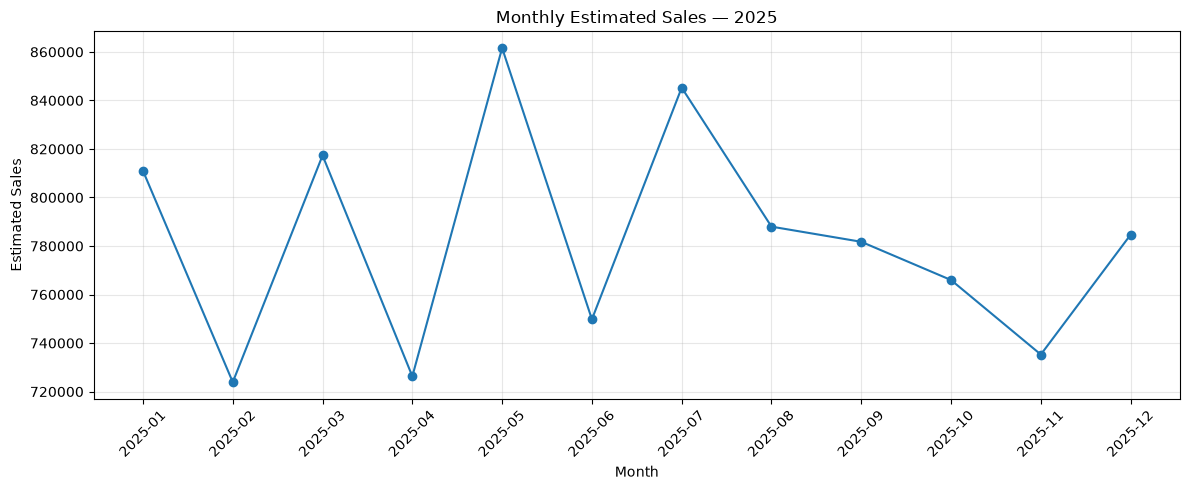


CATEGORY PERFORMANCE


,category,estimated_sales,estimated_margin,transaction_lines
0,Home,1801235.99,562841.57,3141
1,Electronics,1692149.24,525617.04,3286
2,Sports,1666155.45,498419.02,3041
3,Grocery,1655754.72,402579.82,3150
4,Fashion,1377694.92,480517.15,2598
5,Beauty,1197812.78,69056.02,2784



TOP 10 PRODUCTS BY ESTIMATED SALES


,product_id,estimated_sales,estimated_margin,units_sold
0,PR0127,86546.29,17806.29,280
1,PR0022,85578.32,57655.40,268
2,PR0193,83386.13,31434.08,261
3,PR0097,83303.32,57083.08,244
4,PR0185,82317.60,33756.78,253
5,PR0146,80210.45,71454.85,280
6,PR0120,80078.15,49301.05,265
7,PR0220,79411.73,17304.23,250
8,PR0065,78351.79,44736.79,270
9,PR0082,75277.01,38899.61,228



SALES CHANNEL PERFORMANCE


,channel,estimated_sales,estimated_margin,transaction_lines
0,Web,4240209.24,1155871.57,8092
1,App,3671332.69,955258.03,7115
2,Store,1479261.16,427901.02,2793



TRANSACTION STATUS BREAKDOWN


,status,row_count
0,Completed,13962
1,Cancelled,1689
2,Returned,1431
3,Pending,918



EDA step completed.


In [25]:

# -----------------------------
# 8. Exploratory Data Analysis
# -----------------------------

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Work on a copy so the original dataset remains unchanged
eda = df.copy()

eda["timestamp"] = pd.to_datetime(
    eda["timestamp"], errors="coerce"
)

# Choose the available sales and margin columns
sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# Identify available descriptive columns
product_col = next(
    (c for c in ["product_name", "product_id"] if c in eda.columns),
    None
)

category_col = next(
    (c for c in ["category", "product_category"] if c in eda.columns),
    None
)

channel_col = "channel" if "channel" in eda.columns else None
status_col = "status" if "status" in eda.columns else None

# -----------------------------
# 1. Overall sales performance
# -----------------------------

print("=" * 55)
print("OVERALL SALES PERFORMANCE")
print("=" * 55)

print("Transaction lines:", f"{len(eda):,}")
print(
    "Estimated sales:",
    round(eda[sales_col].sum(), 2)
)
print(
    "Estimated margin:",
    round(eda[margin_col].sum(), 2)
)
print(
    "Average estimated sales per line:",
    round(eda[sales_col].mean(), 2)
)
print(
    "Negative-margin lines:",
    int((eda[margin_col] < 0).sum())
)

# -----------------------------
# 2. Monthly sales trend
# -----------------------------

eda["month"] = eda["timestamp"].dt.to_period("M").astype("string")

monthly_sales = (
    eda.dropna(subset=["timestamp"])
    .groupby("month", as_index=False)
    .agg(
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        transaction_lines=("transaction_id", "nunique")
    )
)

print("\nMONTHLY SALES SUMMARY")
display(monthly_sales.round(2))

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["estimated_sales"],
    marker="o"
)
plt.title("Monthly Estimated Sales — 2025")
plt.xlabel("Month")
plt.ylabel("Estimated Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 3. Category performance
# -----------------------------

if category_col:
    category_sales = (
        eda.groupby(category_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            transaction_lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    print("\nCATEGORY PERFORMANCE")
    display(category_sales.round(2))
else:
    print("\nNo recognized product category column found.")

# -----------------------------
# 4. Top 10 products
# -----------------------------

if product_col:
    top_products = (
        eda.groupby(product_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            units_sold=("quantity", "sum")
        )
        .sort_values("estimated_sales", ascending=False)
        .head(10)
        .reset_index()
    )

    print("\nTOP 10 PRODUCTS BY ESTIMATED SALES")
    display(top_products.round(2))
else:
    print("\nNo recognized product identifier column found.")

# -----------------------------
# 5. Sales channel performance
# -----------------------------

if channel_col:
    channel_sales = (
        eda.groupby(channel_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            transaction_lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    print("\nSALES CHANNEL PERFORMANCE")
    display(channel_sales.round(2))

# -----------------------------
# 6. Transaction status breakdown
# -----------------------------

if status_col:
    print("\nTRANSACTION STATUS BREAKDOWN")
    display(
        eda[status_col]
        .value_counts(dropna=False)
        .rename_axis("status")
        .reset_index(name="row_count")
    )

print("\nEDA step completed.")


In [26]:

# -----------------------------
# 9. Completed Transaction Analysis
# -----------------------------

# Filter completed transactions without modifying df
completed = df[
    df["status"].astype("string").str.strip().str.lower()
    == "completed"
].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

print("=" * 55)
print("COMPLETED TRANSACTION ANALYSIS")
print("=" * 55)

# 1. Overall completed transaction performance
print("\n1. Completed transaction summary")
print("Completed lines:", f"{len(completed):,}")
print("Estimated sales:", round(completed[sales_col].sum(), 2))
print("Estimated margin:", round(completed[margin_col].sum(), 2))

if completed[sales_col].sum() != 0:
    print(
        "Estimated margin / sales (%):",
        round(
            completed[margin_col].sum()
            / completed[sales_col].sum() * 100,
            2
        )
    )

print(
    "Negative-margin lines:",
    int((completed[margin_col] < 0).sum())
)

# 2. Category performance
if "category" in completed.columns:
    category_results = (
        completed.groupby("category", dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    category_results["margin_pct"] = (
        category_results["estimated_margin"]
        / category_results["estimated_sales"].replace(0, float("nan"))
        * 100
    )

    print("\n2. Completed sales by category")
    display(category_results.round(2))

# 3. Channel performance
if "channel" in completed.columns:
    channel_results = (
        completed.groupby("channel", dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    channel_results["margin_pct"] = (
        channel_results["estimated_margin"]
        / channel_results["estimated_sales"].replace(0, float("nan"))
        * 100
    )

    print("\n3. Completed sales by channel")
    display(channel_results.round(2))

# 4. Negative-margin investigation
negative_margin = completed[
    completed[margin_col] < 0
].copy()

print("\n4. Negative-margin completed lines")
print("Count:", f"{len(negative_margin):,}")

if len(negative_margin) > 0:
    print(
        "Total estimated negative margin:",
        round(negative_margin[margin_col].sum(), 2)
    )

    if "category" in negative_margin.columns:
        print("\nNegative-margin lines by category:")
        display(
            negative_margin.groupby("category")
            .agg(
                negative_margin_lines=(margin_col, "size"),
                estimated_margin=(margin_col, "sum")
            )
            .sort_values("estimated_margin")
            .round(2)
        )

print("\nCompleted transaction analysis finished.")


COMPLETED TRANSACTION ANALYSIS

1. Completed transaction summary
Completed lines: 13,962
Estimated sales: 7301698.25
Estimated margin: 1968988.4
Estimated margin / sales (%): 26.97
Negative-margin lines: 5315

2. Completed sales by category


,category,estimated_sales,estimated_margin,lines,margin_pct
0,Home,1390889.32,431659.48,2436,31.03
1,Electronics,1316100.72,412263.67,2535,31.32
2,Sports,1301361.92,378860.24,2374,29.11
3,Grocery,1282925.56,300332.44,2437,23.41
4,Fashion,1076686.47,379136.86,2016,35.21
5,Beauty,933734.26,66735.71,2164,7.15



3. Completed sales by channel


,channel,estimated_sales,estimated_margin,lines,margin_pct
0,Web,3320492.10,895102.99,6296,26.96
1,App,2829459.48,742581.55,5499,26.24
2,Store,1151746.67,331303.86,2167,28.77



4. Negative-margin completed lines
Count: 5,315
Total estimated negative margin: -1214115.5

Negative-margin lines by category:


,negative_margin_lines,estimated_margin
category,,
Beauty,1187,-309096.42
Grocery,997,-246611.86
Electronics,952,-184366.60
Home,807,-179804.98
Sports,696,-155494.27
Fashion,676,-138741.37



Completed transaction analysis finished.


In [27]:

# -----------------------------
# Investigate Negative Margins
# -----------------------------

# Use completed transactions only
completed = df[
    df["status"].astype("string").str.strip().str.lower()
    == "completed"
].copy()

margin_col = "estimated_line_margin_before_returns"

negative = completed[completed[margin_col] < 0].copy()

print("Completed transaction lines:", len(completed))
print("Negative-margin completed lines:", len(negative))

print(
    "Percentage with negative margin:",
    round(len(negative) / len(completed) * 100, 2),
    "%"
)

# 1. Inspect example records
columns_to_show = [
    c for c in [
        "transaction_id",
        "product_id",
        "category",
        "quantity",
        "unit_price",
        "discount_pct",
        "unit_cost",
        "gross_line_value",
        "estimated_discounted_line_value",
        margin_col,
    ]
    if c in negative.columns
]

print("\nExample negative-margin records:")
display(negative[columns_to_show].head(15))

# 2. Negative-margin lines by category
if "category" in negative.columns:
    print("\nNegative-margin lines by category:")
    display(
        negative.groupby("category")
        .agg(
            negative_lines=(margin_col, "size"),
            total_negative_margin=(margin_col, "sum"),
            average_negative_margin=(margin_col, "mean")
        )
        .sort_values("total_negative_margin")
        .round(2)
    )

# 3. Compare discounts on negative vs non-negative lines
print("\nDiscount comparison:")
if "discount_pct" in completed.columns:
    completed["margin_group"] = (
        completed[margin_col] < 0
    ).map({
        True: "Negative margin",
        False: "Zero or positive margin"
    })

    display(
        completed.groupby("margin_group", dropna=False)
        .agg(
            lines=(margin_col, "size"),
            average_discount=("discount_pct", "mean"),
            average_unit_price=("unit_price", "mean"),
            average_unit_cost=("unit_cost", "mean"),
            average_margin=(margin_col, "mean")
        )
        .round(3)
    )

print("\nInvestigation complete.")


Completed transaction lines: 13962
Negative-margin completed lines: 5315
Percentage with negative margin: 38.07 %

Example negative-margin records:


,transaction_id,product_id,category,quantity,unit_price,discount_pct,unit_cost,gross_line_value,estimated_discounted_line_value,estimated_line_margin_before_returns
5,TX002062,PR0004,Sports,4,40.94,0.05,88.98,163.76,155.5720,-200.3480
7,TX011958,PR0158,Electronics,3,60.98,0.00,196.78,182.94,182.9400,-407.4000
10,TX001744,PR0247,Sports,2,284.38,0.20,243.07,568.76,455.0080,-31.1320
14,TX008175,PR0008,Beauty,5,30.55,0.15,81.30,152.75,129.8375,-276.6625
18,TX010647,PR0057,Beauty,1,75.51,0.05,129.07,75.51,71.7345,-57.3355
21,TX011493,PR0124,Sports,5,210.78,0.15,223.58,1053.90,895.8150,-222.0850
25,TX016311,PR0172,Home,4,185.34,0.05,207.02,741.36,704.2920,-123.7880
28,TX015197,PR0013,Home,4,174.68,0.15,191.21,698.72,593.9120,-170.9280
30,TX001663,PR0052,Grocery,1,96.02,0.15,155.43,96.02,81.6170,-73.8130
42,TX010428,PR0211,Fashion,3,27.79,0.15,125.04,83.37,70.8645,-304.2555



Negative-margin lines by category:


,negative_lines,total_negative_margin,average_negative_margin
category,,,
Beauty,1187,-309096.42,-260.40
Grocery,997,-246611.86,-247.35
Electronics,952,-184366.60,-193.66
Home,807,-179804.98,-222.81
Sports,696,-155494.27,-223.41
Fashion,676,-138741.37,-205.24



Discount comparison:


,lines,average_discount,average_unit_price,average_unit_cost,average_margin
margin_group,,,,,
Negative margin,5315,0.100,94.863,159.675,-228.432
Zero or positive margin,8647,0.074,246.027,106.120,368.117



Investigation complete.
